In [1]:
# %pip install ultralytics

In [2]:
# import zipfile
# import os
    
# zip_path = "smoke_detection_yolo.zip"
# extract_to = "smoke_detection_yolo"

# # Create folder if it doesn't exist
# os.makedirs(extract_to, exist_ok=True)

# # Unzip
# with zipfile.ZipFile(zip_path, 'r') as zip_ref:
#     zip_ref.extractall(extract_to)

In [3]:
import os

base_path = "smoke_detection_yolo/data"
subsets = ["test", "train",  "val"] # อันนี้เราต้องกำหนดเอง

for subset in subsets: # วนลูป folder ที่กำหนดไว้ในตัวแปร subsets
    img_dir = os.path.join(base_path, subset, "images")
    lbl_dir = os.path.join(base_path, subset, "labels")
    
    img_count = len([f for f in os.listdir(img_dir) if f.endswith((".jpg", ".png"))]) # นับชื่อไฟล์รูปที่ลงท้ายด้วย jpg และ png
    lbl_count = len([f for f in os.listdir(lbl_dir) if f.endswith(".txt")]) # นับชื่อไฟล์เฉลยทุกอัน
    print(f"📁 {subset.upper()}: {img_count} images, {lbl_count} labels")

📁 TEST: 4306 images, 4306 labels
📁 TRAIN: 14122 images, 14122 labels
📁 VAL: 3099 images, 3099 labels


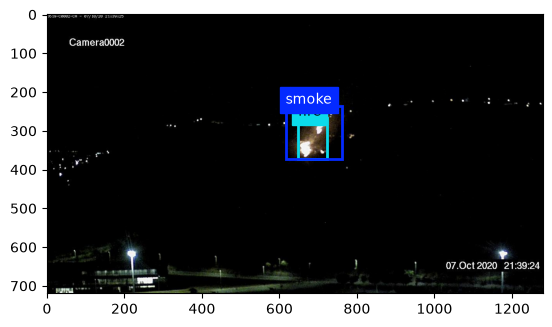

In [4]:
from ultralytics.data.utils import visualize_image_annotations
import yaml

# โหลด class names จาก data.yaml
with open("smoke_detection_yolo/data.yaml", "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)
label_map = {i: name for i, name in enumerate(config["names"])}

# Pick one sample
pair_name = "AoF04161"
image_path = f"smoke_detection_yolo/data/train/images/{pair_name}.jpg"
label_path = f"smoke_detection_yolo/data/train/labels/{pair_name}.txt"

# Visualize โดยเรียกใช้ฟังก์ชัน
visualize_image_annotations(image_path, label_path, label_map)


In [5]:
import matplotlib.pyplot as plt

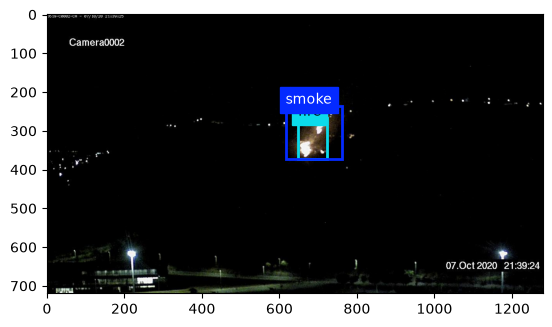

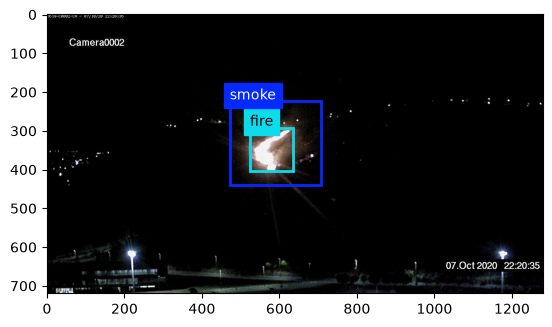

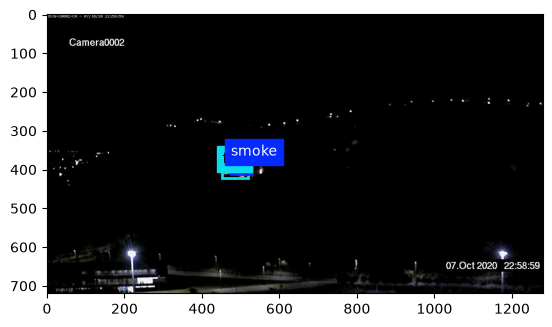

<Figure size 640x480 with 0 Axes>

In [6]:
with open("smoke_detection_yolo/data.yaml", "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)
label_map = {i: name for i, name in enumerate(config["names"])}

# รายชื่อไฟล์ที่ต้องการแสดง (ไม่ต้องใส่นามสกุล)
pair_names = [
    "AoF04161",
    "AoF04281",
    "AoF04351",
]

# วน loop แสดงแต่ละภาพ
for i, pair_name in enumerate(pair_names, start=1):
    image_path = f"smoke_detection_yolo/data/train/images/{pair_name}.jpg"
    label_path = f"smoke_detection_yolo/data/train/labels/{pair_name}.txt"
    
    # ตรวจสอบว่าไฟล์มีอยู่จริง
    if os.path.exists(image_path) and os.path.exists(label_path):
        visualize_image_annotations(image_path, label_path, label_map)
    else:
        print(f"👒 ไฟล์หนะไม่มีอยู่จริงงง: {pair_name}🏴‍☠️")

plt.tight_layout()
plt.show()

In [18]:
# from ultralytics import YOLO

# # Load a model
# model = YOLO("yolov8m.pt")

In [8]:
# %pip install "numpy<2.0.0"

In [20]:
# model.train(
#     data="smoke_detection_yolo/data.yaml",  # Path to your YAML file
#     epochs=1,                                  # Number of training epochs
#     imgsz=640,                                  # Image size (default is 640)
#     batch=32,                                   # Batch size (adjust to your GPU)
#     name="smoke_detection_yolo"                # Custom run name
# )

In [10]:
# from ultralytics import YOLO
# model = YOLO("yolo26s.pt")
# model.train(
#     data="smoke_detection_yolo/data.yaml",  # Path to your YAML file
#     epochs=5,                                  # Number of training epochs
#     imgsz=640,                                  # Image size (default is 640)
#     batch=32,                                   # Batch size (adjust to your GPU)
#     name="smoke_detection_yolo"                # Custom run name
# )

In [11]:
import yaml
import os

# Define the path where we will save our custom hyperparameter configuration
hyp_yaml_path = os.path.join(base_path, "custom_hyp.yaml")

# Define the custom augmentation hyperparameters tailored for Fire/Smoke
custom_hyperparameters = {
    # --- Optimization/Base Params ---
    'lr0': 0.01,           # initial learning rate (i.e. SGD=1E-2, Adam=1E-3)
    'lrf': 0.01,           # final OneCycleLR learning rate (lr0 * lrf)
    'momentum': 0.937,     # SGD momentum/Adam beta1
    'weight_decay': 0.0005,# optimizer weight decay
    'warmup_epochs': 3.0,  # warmup epochs (fractions ok)
    'warmup_momentum': 0.8,# warmup initial momentum
    'warmup_bias_lr': 0.1, # warmup initial bias lr
    
    # --- Box/Loss Weights ---
    'box': 7.5,            # box loss gain (YOLOv8 default)
    'cls': 0.5,            # cls loss gain (YOLOv8 default)
    'dfl': 1.5,            # dfl loss gain (YOLOv8 default)
    
    # --- Custom Fire/Smoke Augmentations ---
    'hsv_h': 0.015,        # image HSV-Hue augmentation (fraction). Keep LOW to preserve fire color.
    'hsv_s': 0.7,          # image HSV-Saturation augmentation (fraction). High to simulate vivid fire/faded smoke.
    'hsv_v': 0.4,          # image HSV-Value augmentation (fraction). Simulate day/night lighting.
    'degrees': 5.0,        # image rotation (+/- deg). Slight tilt is fine.
    'translate': 0.1,      # image translation (+/- fraction)
    'scale': 0.5,          # image scale (+/- gain)
    'shear': 0.0,          # image shear (+/- deg). Disabled.
    'perspective': 0.0,    # image perspective (+/- fraction), range 0-0.001. Disabled.
    
    # --- Physical Orientation Constraints ---
    'fliplr': 0.5,         # image flip left-right (probability). 50% chance is good.
    'flipud': 0.0,         # image flip up-down (probability). STRICTLY 0. Fire/smoke only goes up!
    
    # --- Mosaic & Mixup ---
    'mosaic': 1.0,         # image mosaic (probability). 100% is great for context.
    'mixup': 0.0,          # image mixup (probability). Disabled to avoid ghosting artifacts.
    'copy_paste': 0.0      # segment copy-paste (probability). Disabled.
}

# Save to YAML
with open(hyp_yaml_path, "w", encoding="utf-8") as f:
    yaml.dump(custom_hyperparameters, f, sort_keys=False)

print(f"✅ Custom augmentation hyperparameters saved to: {hyp_yaml_path}")

# Display the contents to verify
print("\n--- Current Augmentation Profile ---")
with open(hyp_yaml_path, 'r') as f:
    print(f.read())

✅ Custom augmentation hyperparameters saved to: smoke_detection_yolo/data/custom_hyp.yaml

--- Current Augmentation Profile ---
lr0: 0.01
lrf: 0.01
momentum: 0.937
weight_decay: 0.0005
warmup_epochs: 3.0
warmup_momentum: 0.8
warmup_bias_lr: 0.1
box: 7.5
cls: 0.5
dfl: 1.5
hsv_h: 0.015
hsv_s: 0.7
hsv_v: 0.4
degrees: 5.0
translate: 0.1
scale: 0.5
shear: 0.0
perspective: 0.0
fliplr: 0.5
flipud: 0.0
mosaic: 1.0
mixup: 0.0
copy_paste: 0.0



In [2]:
from ultralytics import YOLO

In [3]:
# Load a model
model = YOLO("yolov8n.pt")
model.train(
    data="smoke_detection_yolo/custom_hyp.yaml",  # Path to your YAML file
    epochs=50,                                  # Number of training epochs
    imgsz=640,                                  # Image size (default is 640)
    batch=32,                                   # Batch size (adjust to your GPU)
    name="train_use_yolov8n"                # Custom run name
)

New https://pypi.org/project/ultralytics/8.4.175 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.173 🚀 Python-3.11.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition MIG 1g.24gb, 24192MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=smoke_detection_yolo/custom_hyp.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7fd20f8c5150>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

In [1]:
from ultralytics import YOLO
# Load a model
model = YOLO("yolov8s.pt")
model.train(
    data="smoke_detection_yolo/data.yaml",  # Path to your YAML file
    cfg = "smoke_detection_yolo/custom_hyp.yaml",
    epochs=50,                                  # Number of training epochs
    imgsz=640,                                  # Image size (default is 640)
    batch=16,                                   # Batch size (adjust to your GPU)
    name="run_detect_yolov8s",                # Custom run name
    cache = "disk"
)

New https://pypi.org/project/ultralytics/8.4.175 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.173 🚀 Python-3.11.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition MIG 1g.24gb, 24192MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=disk, cfg=smoke_detection_yolo/custom_hyp.yaml, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=smoke_detection_yolo/data.yaml, degrees=5.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7eaf0c365290>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804